CLUSTERING ANALYSIS 

Data Preprocessing:     
1.	Preprocess the dataset to handle missing values, remove outliers, and scale the features if necessary.      
2.	Perform exploratory data analysis (EDA) to gain insights into the distribution of data and identify potential clusters.     
3.	Use multiple visualizations to understand the hidden patterns in the dataset


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
df=pd.read_excel('EastWestAirlines - Copy.xlsx',sheet_name='data')

In [31]:
df.columns

Index(['Balance', 'Qual_miles', 'cc1_miles', 'cc2_miles', 'cc3_miles',
       'Bonus_miles', 'Bonus_trans', 'Flight_miles_12mo', 'Flight_trans_12',
       'Days_since_enroll', 'Award?'],
      dtype='str')

In [8]:
df.head()

,ID#,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
0,1,28143,0,1,1,1,174,1,0,0,7000,0
1,2,19244,0,1,1,1,215,2,0,0,6968,0
2,3,41354,0,1,1,1,4123,4,0,0,7034,0
3,4,14776,0,1,1,1,500,1,0,0,6952,0
4,5,97752,0,4,1,1,43300,26,2077,4,6935,1


In [9]:
df.drop(columns=['ID#'],inplace=True)

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3999 entries, 0 to 3998
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   Balance            3999 non-null   int64
 1   Qual_miles         3999 non-null   int64
 2   cc1_miles          3999 non-null   int64
 3   cc2_miles          3999 non-null   int64
 4   cc3_miles          3999 non-null   int64
 5   Bonus_miles        3999 non-null   int64
 6   Bonus_trans        3999 non-null   int64
 7   Flight_miles_12mo  3999 non-null   int64
 8   Flight_trans_12    3999 non-null   int64
 9   Days_since_enroll  3999 non-null   int64
 10  Award?             3999 non-null   int64
dtypes: int64(11)
memory usage: 343.8 KB


In [11]:
df.shape

(3999, 11)

In [12]:
df.duplicated().sum()

np.int64(1)

In [13]:
df.isnull().sum()

Balance              0
Qual_miles           0
cc1_miles            0
cc2_miles            0
cc3_miles            0
Bonus_miles          0
Bonus_trans          0
Flight_miles_12mo    0
Flight_trans_12      0
Days_since_enroll    0
Award?               0
dtype: int64

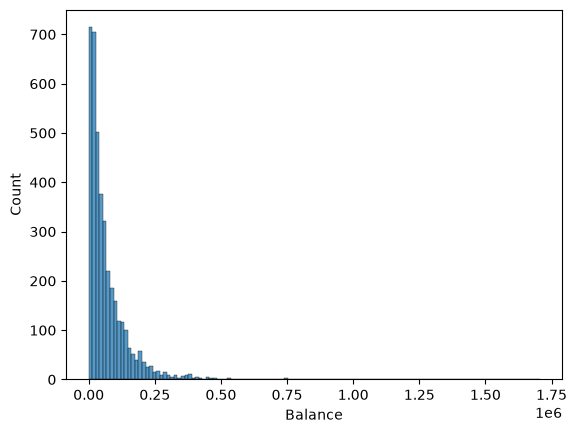

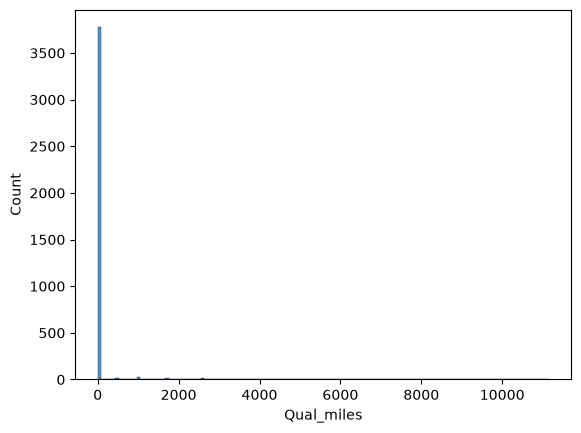

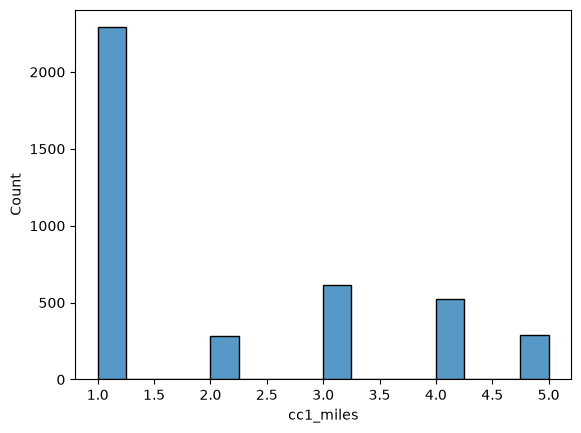

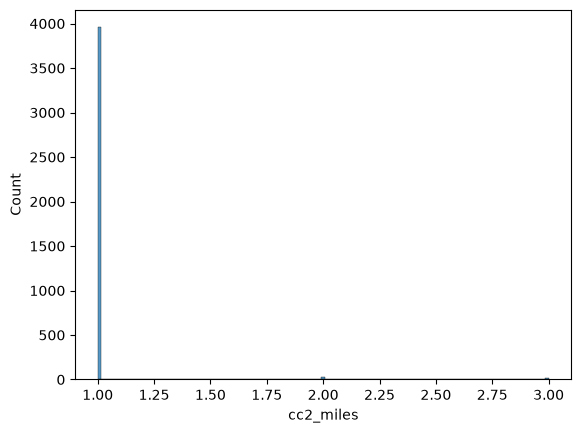

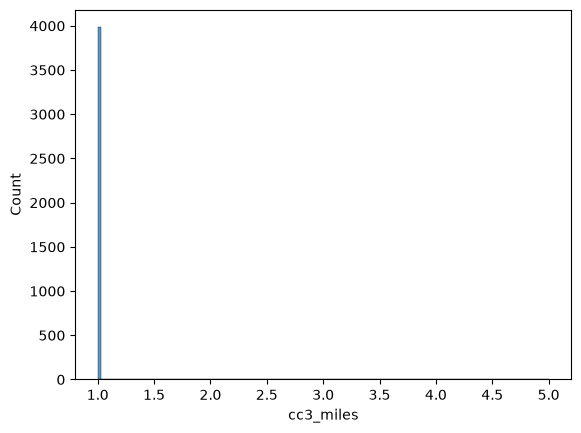

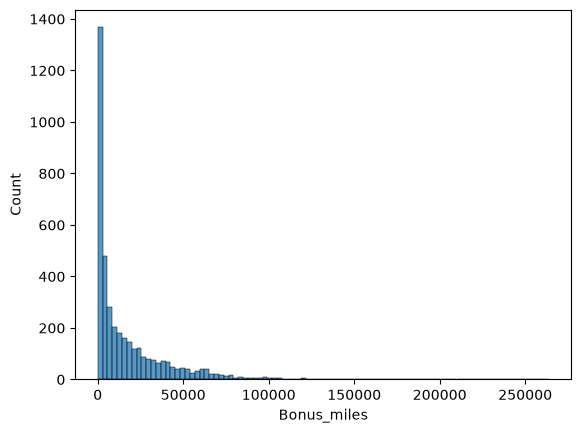

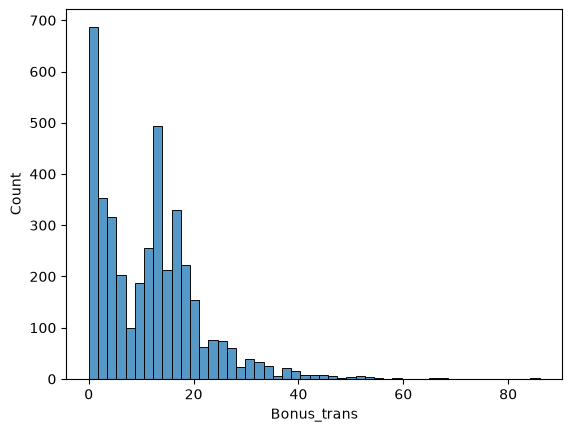

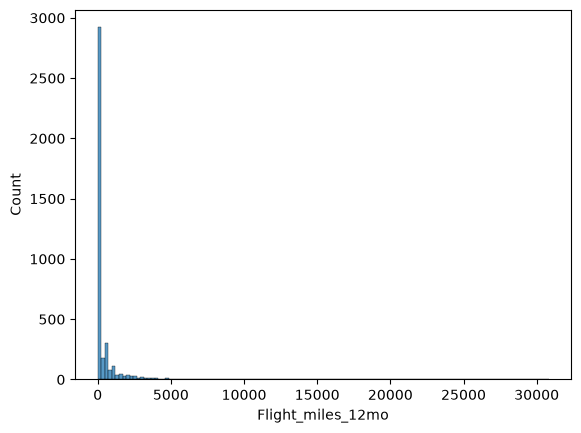

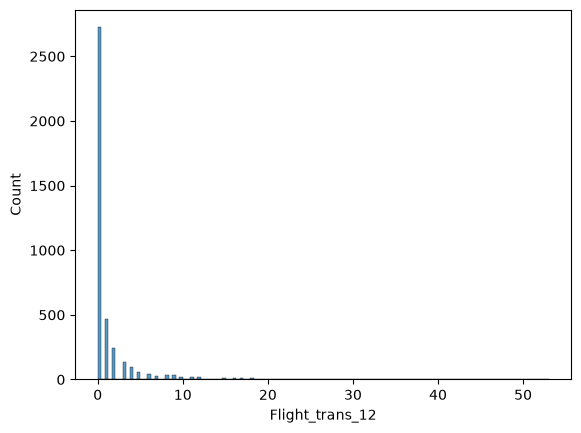

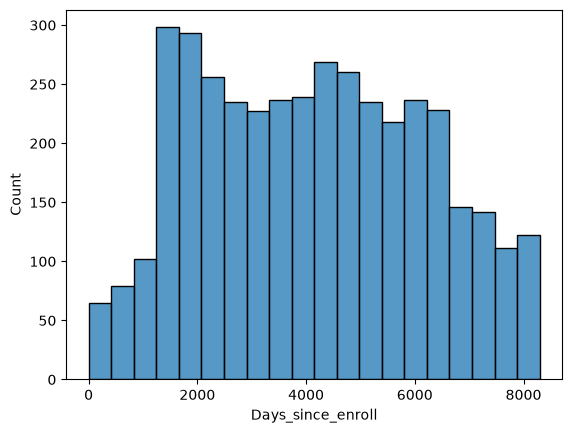

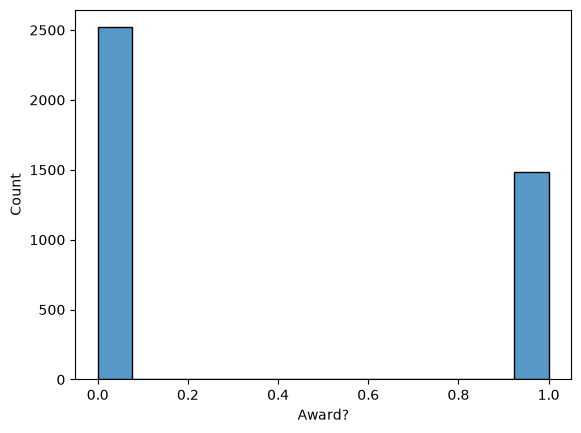

In [14]:
for i in df.columns:
    sns.histplot(df[i])
    plt.show()

In [15]:
target=df['Award?']
features=df.drop(columns=['Award?'])

In [16]:
from sklearn.feature_selection import f_classif

In [17]:
f_cls=f_classif(features,target)

In [18]:
pd.DataFrame(f_cls[0],index=features.columns)

,0
Balance,131.535245
Qual_miles,36.599901
cc1_miles,506.819999
cc2_miles,0.113642
cc3_miles,2.205629
Bonus_miles,648.010756
Bonus_trans,501.514560
Flight_miles_12mo,198.884172
Flight_trans_12,261.737297
Days_since_enroll,146.641538


In [19]:
features=features.drop(columns=['Qual_miles','cc2_miles','cc3_miles'])

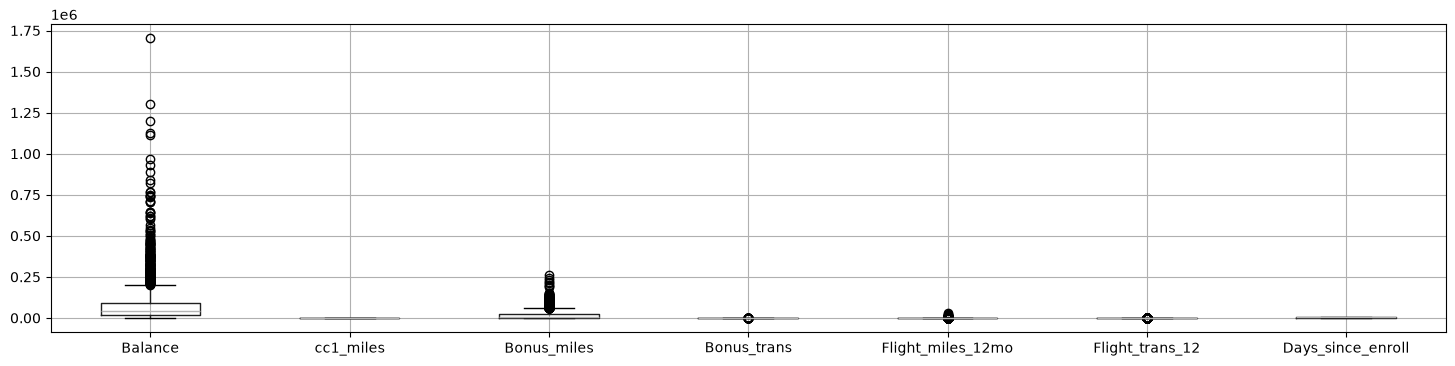

In [20]:
plt.figure(figsize=(18,4))
features.boxplot()
plt.show()

In [21]:
#### outlier capping
last_col=df.columns[-1]
def outlier_capping(df,column):
    Q1= df[column].quantile(0.25)
    Q3= df[column].quantile(0.75)
    IQR= Q3-Q1
    lower_extreme= Q1-1.5*IQR
    upper_extreme= Q3+1.5*IQR
    df[column]= df[column].apply(lambda x: lower_extreme if x< lower_extreme else upper_extreme if x>upper_extreme else x)
for col in features.select_dtypes(include=['int','float']).columns:
    outlier_capping(features,col)

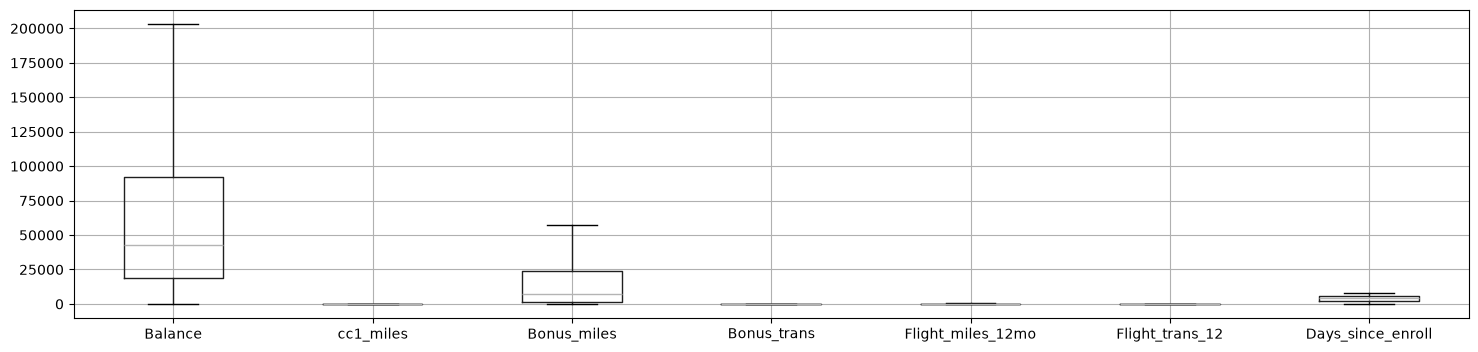

In [22]:
plt.figure(figsize=(18,4))
features.boxplot()
plt.show()

<Axes: >

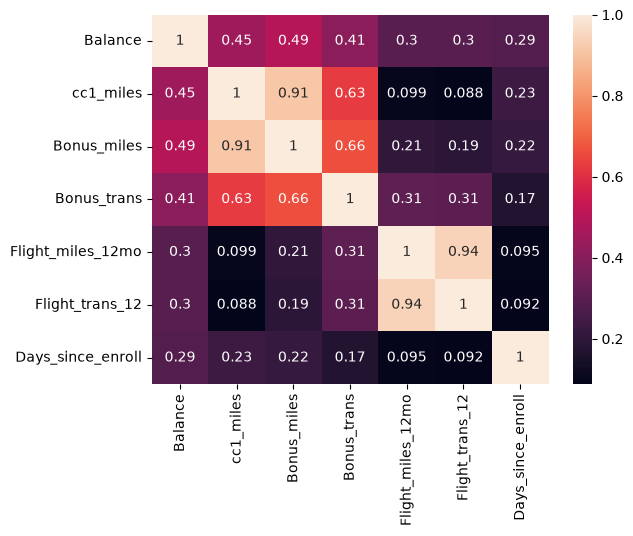

In [23]:
cor=features.corr()
sns.heatmap(cor,annot=True)

Implementing Clustering Algorithms:     
•	Implement the K-Means and DBSCAN algorithms using a programming language such as Python with libraries like scikit-learn.       
•	Apply each clustering algorithm to the pre-processed dataset to identify clusters within the data.      
•	Experiment with different parameter settings for K-means (Elbow curve for different K values) and DBSCAN (e.g., epsilon, minPts) and evaluate the clustering results.


In [24]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans,DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors

In [25]:
std_sca=StandardScaler()

In [ ]:
features=std_sca.fit_transform(features)

In [32]:
df_scaled=pd.DataFrame(features,columns=['Balance','cc1_miles',
       'Bonus_miles', 'Bonus_trans', 'Flight_miles_12mo', 'Flight_trans_12',
       'Days_since_enroll'])

In [33]:
df_scaled

,Balance,cc1_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll
0,-0.607258,-0.769578,-0.843091,-1.148854,-0.604313,-0.626143,1.395454
1,-0.758947,-0.769578,-0.840822,-1.039133,-0.604313,-0.626143,1.379957
2,-0.382070,-0.769578,-0.624581,-0.819689,-0.604313,-0.626143,1.411920
3,-0.835106,-0.769578,-0.825052,-1.148854,-0.604313,-0.626143,1.372208
4,0.579265,1.409471,1.543191,1.594189,2.034489,2.020176,1.363975
...,...,...,...,...,...,...,...
3994,-0.772038,-0.769578,-0.381007,-0.819689,0.074478,0.432384,-1.315120
3995,0.010506,-0.769578,-0.798437,-0.709967,-0.604313,-0.626143,-1.318994
3996,0.167530,0.683121,0.555335,-0.380802,-0.604313,-0.626143,-1.315604
3997,-0.151188,-0.769578,-0.825052,-1.148854,1.092666,0.432384,-1.316088


In [34]:
wcss=[]
s_score=[]
k_range=(2,11)

In [35]:
for k in k_range:
    kmeans=KMeans(n_clusters=k,random_state=42,n_init=10)
    labels=kmeans.fit_predict(df_scaled)
    wcss.append(kmeans.inertia_)
    s_score.append(silhouette_score(df_scaled,labels))

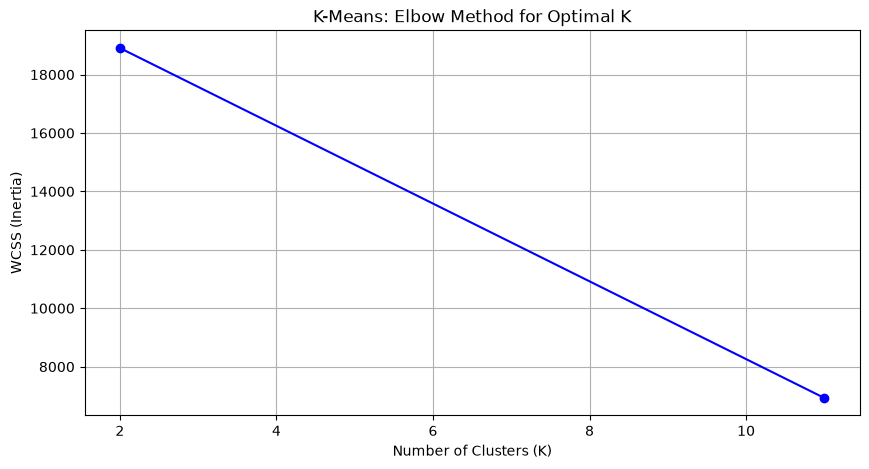

In [39]:
#Plot elbow curve
plt.figure(figsize=(10, 5))
plt.plot(k_range,wcss,marker='o',linestyle='-',color='b')
plt.title('K-Means: Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS (Inertia)')
plt.grid(True)
plt.show()

In [40]:
minpts=22
neighbours=NearestNeighbors(n_neighbors=minpts)
neighbours_fit=neighbours.fit(df_scaled)
distances,indices=neighbours_fit.kneighbors(df_scaled)
distances=np.sort(distances[:,-1],axis=0)

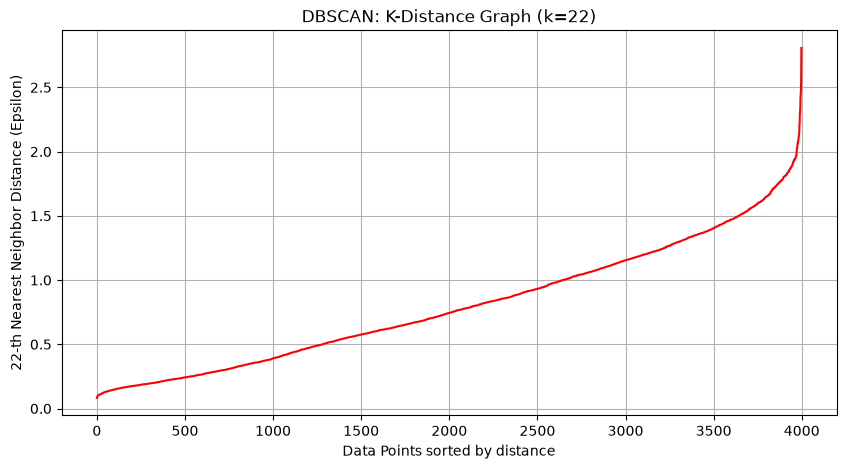

In [43]:
plt.figure(figsize=(10,5))
plt.plot(distances,color='r')
plt.title(f'DBSCAN: K-Distance Graph (k={minpts})')
plt.xlabel('Data Points sorted by distance')
plt.ylabel(f'{minpts}-th Nearest Neighbor Distance (Epsilon)')
plt.grid(True)
plt.show()

In [44]:
dbscan_results=[]
eps_values=[1.5, 2.0, 2.5, 3.0, 3.5]
for eps in eps_values:
    db=DBSCAN(eps=eps,min_samples=minpts).fit(df_scaled)
    labels=db.labels_
    n_clusters=len(set(labels))-(1 if -1 in labels else 0)
    n_noise=list(labels).count(-1)
    if n_clusters > 1:
        sil=silhouette_score(df_scaled,labels)
    else:
        sil=-1
    dbscan_results.append({'Eps': eps,'Clusters': n_clusters,'Noise Points': n_noise,'Silhouette': sil})

In [47]:
dbscan_df=pd.DataFrame(dbscan_results)
print("K-Means Silhouette Scores:",dict(zip(k_range,[round(s,4) for s in s_score])))
print("\nDBSCAN Tuning Results:")
print(dbscan_df.to_string(index=False))

K-Means Silhouette Scores: {2: 0.3422, 11: 0.2654}

DBSCAN Tuning Results:
 Eps  Clusters  Noise Points  Silhouette
 1.5         1            36          -1
 2.0         1             2          -1
 2.5         1             0          -1
 3.0         1             0          -1
 3.5         1             0          -1


Cluster Analysis and Interpretation:        
•	Analyse the clusters generated by each clustering algorithm and interpret the characteristics of each cluster. Write you insights in few comments.


In [54]:
kmeans = KMeans(n_clusters=6, random_state=42, n_init=10)
df_scaled['KMeans_Cluster'] = kmeans.fit_predict(df_scaled)

In [55]:
print("K-Means Cluster Means:")
kmeans_summary = df_scaled.groupby('KMeans_Cluster').mean().round(2)
print(kmeans_summary[['Balance','Bonus_miles','Bonus_trans','Flight_miles_12mo']])
print(f"\nK-Means Cluster Counts:\n{df_scaled['KMeans_Cluster'].value_counts()}")

K-Means Cluster Means:
                Balance  Bonus_miles  Bonus_trans  Flight_miles_12mo
KMeans_Cluster                                                      
0                 -0.14         0.13         0.56              -0.49
1                 -0.35        -0.65        -0.64              -0.54
2                  0.89         1.51         0.70              -0.52
3                  0.24        -0.42        -0.08               1.62
4                  1.07         1.58         1.47               1.62
5                 -0.64        -0.72        -0.77              -0.54

K-Means Cluster Counts:
KMeans_Cluster
5    993
1    800
0    715
3    590
2    515
4    386
Name: count, dtype: int64


In [56]:
dbscan = DBSCAN(eps=1.5, min_samples=22)
df_scaled['DBSCAN_Cluster'] = dbscan.fit_predict(df_scaled)

In [57]:
print("\n---")
print("\nDBSCAN Cluster Means:")
dbscan_summary = df_scaled.groupby('DBSCAN_Cluster').mean().round(2)
print(dbscan_summary[['Balance','Bonus_miles', 'Bonus_trans', 'Flight_miles_12mo']])
print(f"\nDBSCAN Cluster Counts:\n{df_scaled['DBSCAN_Cluster'].value_counts()}")


---

DBSCAN Cluster Means:
                Balance  Bonus_miles  Bonus_trans  Flight_miles_12mo
DBSCAN_Cluster                                                      
-1                 1.19         0.91         1.70               1.07
 0                -0.35        -0.65        -0.64              -0.54
 1                 1.04         1.65         1.40               1.68
 2                 0.89         1.51         0.70              -0.52
 3                -0.14         0.13         0.55              -0.49
 4                 0.21        -0.44        -0.11               1.64
 5                -0.64        -0.72        -0.77              -0.54

DBSCAN Cluster Counts:
DBSCAN_Cluster
 5    993
 0    800
 3    712
 4    573
 2    514
 1    336
-1     71
Name: count, dtype: int64


In [58]:
print("""      

The K-Means clustering algorithm reveals distinct behavioral segments within the airline's customer base, 
highlighting a large majority of inactive, occasional flyers with low balances who rarely redeem awards. 
In contrast, it also identifies highly engaged niche groups, such as elite frequent flyers who dominate actual 
flight miles, and credit card maximizers who accumulate massive balances entirely through bonus transactions. 
Meanwhile, the DBSCAN algorithm provides a broader, density-based perspective by splitting the standard customer 
base into two primary groups: members who have never redeemed an award and members who have. Furthermore, DBSCAN 
effectively isolates the most exceptionally active, high-value customers—those with massive balances and extreme 
transaction volumes—by classifying them as "noise" or outliers, completely separating them from the general population.

""")

      

The K-Means clustering algorithm reveals distinct behavioral segments within the airline's customer base, 
highlighting a large majority of inactive, occasional flyers with low balances who rarely redeem awards. 
In contrast, it also identifies highly engaged niche groups, such as elite frequent flyers who dominate actual 
flight miles, and credit card maximizers who accumulate massive balances entirely through bonus transactions. 
Meanwhile, the DBSCAN algorithm provides a broader, density-based perspective by splitting the standard customer 
base into two primary groups: members who have never redeemed an award and members who have. Furthermore, DBSCAN 
effectively isolates the most exceptionally active, high-value customers—those with massive balances and extreme 
transaction volumes—by classifying them as "noise" or outliers, completely separating them from the general population.




Visualization:      
Visualize the clustering results using scatter plots or other suitable visualization techniques.        
Plot the clusters with different colours to visualize the separation of data points belonging to different clusters.


In [59]:
from sklearn.decomposition import PCA

In [60]:
# Reduce dimensions to 2D using PCA for visualization
pca = PCA(n_components=2)
df_pca = pca.fit_transform(df_scaled)

In [64]:
kmeans = KMeans(n_clusters=6, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(df_scaled)

dbscan = DBSCAN(eps=1.5, min_samples=22)
dbscan_labels = dbscan.fit_predict(df_scaled)

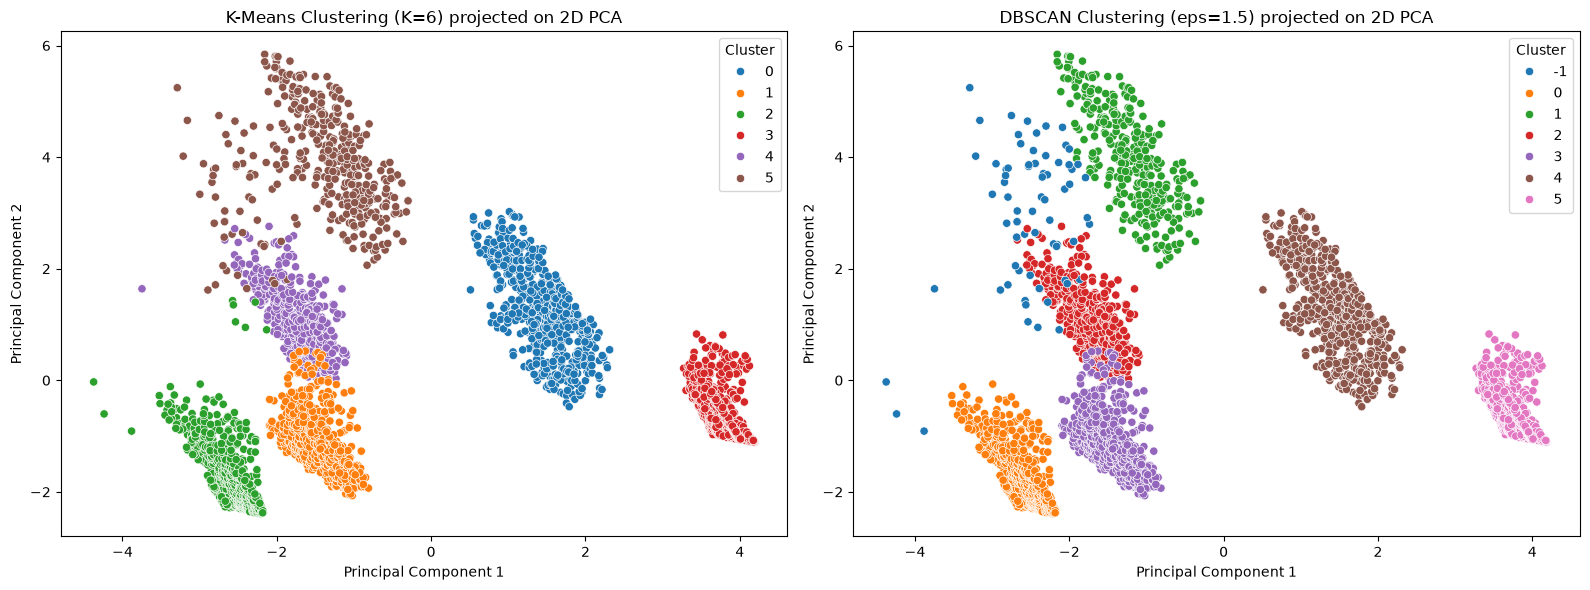

In [71]:
# Plotting
plt.figure(figsize=(16, 6))

# K-Means Plot
plt.subplot(1, 2, 1)
sns.scatterplot(x=df_pca[:, 0], y=df_pca[:, 1],hue=kmeans_labels,palette='tab10')
plt.title('K-Means Clustering (K=6) projected on 2D PCA')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Cluster')

# DBSCAN Plot
plt.subplot(1, 2, 2)
sns.scatterplot(x=df_pca[:, 0], y=df_pca[:, 1],hue=dbscan_labels,palette='tab10')
plt.title('DBSCAN Clustering (eps=1.5) projected on 2D PCA')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Cluster')

plt.tight_layout()
plt.show()

Evaluation and Performance Metrics:     
Evaluate the quality of clustering using internal evaluation metrics such as silhouette score for K-Means and DBSCAN.


In [74]:
sil_kmeans = silhouette_score(df_scaled, kmeans.labels_)
print(f"K-Means (K=2) Silhouette Score: {sil_kmeans:.4f}")


db_labels = dbscan.labels_
n_clusters = len(set(db_labels)) - (1 if -1 in db_labels else 0)

if n_clusters > 1:
    sil_dbscan = silhouette_score(df_scaled, db_labels)
    print(f"DBSCAN Silhouette Score: {sil_dbscan:.4f}")
else:
    print("DBSCAN did not find more than 1 cluster. Silhouette score cannot be calculated.")

K-Means (K=2) Silhouette Score: 0.5273
DBSCAN Silhouette Score: 0.5240
